In [ ]:
!pip install -q torch matplotlib

# data acquisition
!pip install -q wxee

# data preprocessing
!pip install -q rasterio #scipy

# **IMPORTS**

In [1]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import os

# ---------- Google Earth Engine authentication and initialization
# import StringIO
import ee
import wxee

from dotenv import load_dotenv
load_dotenv()
ee.Authenticate()
ee.Initialize(project=os.getenv("EAI_PROJECT_ID"))
#from google.colab import userdata
#ee.Initialize(project=userdata.get('EAI_project_ID'))

# ---------- data
from torch.utils.data import IterableDataset, DataLoader

# ---------- preprocessing
import torch.nn.functional as F
import math

# ---------- testing and visualization
import matplotlib.pyplot as plt

/home/filippo/Scrivania/electiveAI/Spectral-Spatial-Anomaly-Detection/venv/lib/python3.10/site-packages/google/api_core/_python_version_support.py:275: FutureWarning: You are using a Python version (3.10.12) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)
/home/filippo/Scrivania/electiveAI/Spectral-Spatial-Anomaly-Detection/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# **GLOBALS**

# **DATA**

## Preprocessing

In [6]:
class PatchExtractor:
    """
        Extract patches from input image tensor.
        Runs on CPU (in dataset).
    """
    def __init__(self, patch_size, stride=None, scale_factor=None):
        self.patch_size = patch_size
        self.stride = stride if stride is not None else patch_size
        self.scale_factor = scale_factor

    def __call__(self, img_tensor):
        # --- Rescaling
        if self.scale_factor:
            img_tensor = F.interpolate(
                img_tensor.unsqueeze(0), scale_factor=self.scale_factor,
                mode='bilinear', align_corners=False
            ).squeeze(0)
        
        C, H, W = img_tensor.shape

        # --- Padding
        pad_h = (self.patch_size - (H % self.patch_size)) % self.patch_size
        pad_w = (self.patch_size - (W % self.patch_size)) % self.patch_size
        if pad_h > 0 or pad_w > 0:
            img_tensor = F.pad(img_tensor, (0, pad_w, 0, pad_h), mode='reflect')

        # --- Patch Extraction
        img_tensor = img_tensor.unsqueeze(0)  # (1, C, H, W)
        patches = img_tensor.unfold(2, self.patch_size, self.stride).unfold(3, self.patch_size, self.stride)    # (1, C, H_steps, W_steps, patch_H, patch_W)
        patches = patches.contiguous().view(-1, C, self.patch_size, self.patch_size)    # (Num_Patches, C, patch_H, patch_W)
        
        return patches

In [ ]:
class SpectralDCT(nn.Module):
    """
        Apply DCT to each patch along the spectral dimension.
        Runs on the GPU (in training loop).
    """
    def __init__(self, num_bands):
        super().__init__()
        # Create matrix and register it as a buffer. 
        # This ensures it moves to the GPU when you do `spectral_dct.cuda()`
        dct_matrix = self._create_dct_matrix(num_bands)
        self.register_buffer('dct_matrix', dct_matrix)

    def _create_dct_matrix(self, N):    # Type-II DCT matrix
        # spectral signature vector:      X = (x_1, x_2, ..., x_N)
        # Formula:        DCT_output_k = norm_coeff_k * sum_n (x_n * cos(pi/N * (n+0.5) * k))
        # Matrix form:    DCT_output = M * X      with    M = norm_coeffs * cos(pi/N * (n+0.5) * k)   (n: (1, N), k: (N, 1), M: (N, N))

        k = torch.arange(N).unsqueeze(1).float()  # k = (0; 1; 2; ...; N-1), shape (N, 1), k rows: output frequencies
        n = torch.arange(N).unsqueeze(0).float()  # n = (0, 1, 2, ..., N-1), shape (1, N), n columns: input bands

        # basis function (core cosine term)
        M = torch.cos((math.pi / N) * (n + 0.5) * k)   # (N, N)

        # orthonormalization coefficients (scaling coeffs to ensure the transform is orthonormal)
        norm_coeffs = torch.ones(N, 1) * math.sqrt(2 / N)   # k > 0 components scaled by sqrt(2/N)
        norm_coeffs[0, 0] = 1 / math.sqrt(N)    # k = 0 component scaled by sqrt(1/N)
        M *= norm_coeffs

        return M    # (N, N) with N = C (num_bands)

    def forward(self, patches):
        # apply 1D DCT to the Channel dimension (dim 1)
        # patches: (Num_Patches, C, patch_H, patch_W)

        # move Channels (spectral vector) to the last dimension
        patches_permuted = patches.permute(0, 2, 3, 1)  # X^T (Num_Patches, patch_H, patch_W, C)

        # DCT-II formula (matrix form): DCT_output^T = X^T * M^T
        dct_patches = torch.matmul(patches_permuted, self.dct_matrix.t())   # (Num_Patches, patch_H, patch_W, C)

        # permute back to (Num_Patches, C, patch_H, patch_W)
        return dct_patches.permute(0, 3, 1, 2)

## Stream of Sentinel-2 data

In [8]:
class Sentinel2Stream(IterableDataset):
    def __init__(self, rois, time_interval, bands_to_use, preprocessor, chunk_months=3):
        self.rois = rois                        # list of ee.Geometry.Rectangle objects (regions of interest)
        self.time_start = time_interval[0]      # string (e.g. '2020-01-01')
        self.time_end = time_interval[1]        # string (e.g. '2020-12-31')
        self.chunk_months = chunk_months        # number of months to fetch in each chunk (to manage memory)

        self.bands_to_use = bands_to_use
        self.preprocessor = preprocessor

    def _generate_time_chunks(self):
        """ 
            Split the time range into smaller intervals
        """
        dates = pd.date_range(start=self.time_start, end=self.time_end, freq=f'{self.chunk_months}ME')
        # Add the start date if not included
        intervals = []
        
        start_date = pd.Timestamp(self.time_start)
        for end_date in dates:
            if end_date > start_date:
                intervals.append((start_date.strftime('%Y-%m-%d'), end_date.strftime('%Y-%m-%d')))
                start_date = end_date
        
        # Handle remaining time after the last chunk
        final_end = pd.Timestamp(self.time_end)
        if start_date < final_end:
            intervals.append((start_date.strftime('%Y-%m-%d'), final_end.strftime('%Y-%m-%d')))
             
        return intervals

    def stream_generator(self):
        # Loop through the regions of interest
        for roi_idx, roi in enumerate(self.rois):

            time_chunks = self._generate_time_chunks()
            # Loop through time chunks
            for (t_start, t_end) in time_chunks:

                try:
                    # --------------- define the image collection
                    s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                          .filterBounds(roi)
                          .filterDate(t_start, t_end)
                          .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 30))    # discard images more than 30% cloudy
                          .select(self.bands_to_use)
                        )
                    # Check if collection is empty before downloading
                    if s2.size().getInfo() == 0: continue

                    # --------------- download the images (from the roi at the specified time interval) into the RAM
                    ts = wxee.TimeSeries(s2)    # create time series
                    # fetch into RAM (Lazy Loading)
                    ds = ts.wx.to_xarray(region=roi, scale=10, progress=False)  # resampling at scale

                    # --------------- convert data to numpy
                    # stack bands
                    data = np.stack([ds[b].values for b in self.bands_to_use], axis=1)    # (TimeSteps, Channels, H, W)

                    # --------------- preprocess
                    # normalize
                    data = data.astype(float) / 10000.0
                    data = np.nan_to_num(data)    # handle missing pixels

                    timesteps = data.shape[0]
                    for i in range(timesteps):  # iterate through all images
                        img_tensor = torch.from_numpy(data[i]).float()    # convert to tensor (Channels, H, W)

                        # skip mostly black/empty images
                        if img_tensor.max() == 0 or img_tensor.mean() < 0.001: continue

                        # ------- yield preprocessed patches
                        patches_batch = self.preprocessor(img_tensor)   # (Num_Patches, C, patch_H, patch_W)
                        for patch in patches_batch:
                          # skip mostly black/empty patches
                          if patch.max() == 0: continue
                          yield patch     # (C, patch_H, patch_W)

                except Exception as e:
                    print(f"Skipping time chunk {t_start}-{t_end} in ROI {roi_idx}, error: {e}")
                    continue

    def __iter__(self):
        return iter(self.stream_generator())

# **NETWORK**  <-- To check

In [ ]:
class model_1():
  def __init__(self, in_channels, hidden_transformer_dimension, out_channels):
    self.in_channels = in_channels
    self.out_channels = out_channels
    self.hidden_transformer_dimension = hidden_transformer_dimension

    # first MLP
    self.mlp1 = torch.nn.Sequential(
        torch.nn.Linear(in_features=self.in_channels, out_features=128),
        torch.nn.ReLU(),
        torch.nn.Linear(in_features=128, out_features=64),
        torch.nn.ReLU(),
        torch.nn.Linear(in_features=64, out_features=32),
        torch.nn.ReLU(),
        torch.nn.Linear(in_features=32, out_features=self.out_channels)
    )
    # first linear layer (instead of the first MLP)
    self.linear1 = torch.nn.Linear(in_features=self.in_channels, out_features=self.hidden_transformer_dimension)

    # Transformer encoder
    self.transformer_encoder = torch.nn.TransformerEncoder(
        encoder_layer=torch.nn.TransformerEncoderLayer(d_model=self.hidden_transformer_dimension, nhead=6),
        num_layers=4
    )

    # decoder MLP
    self.decoder = torch.nn.Sequential(
        torch.nn.Linear(in_features=self.hidden_transformer_dimension, out_features=64),
        torch.nn.ReLU(),
        torch.nn.Linear(in_features=64, out_features=128),
        torch.nn.ReLU(),
        torch.nn.Linear(in_features=128, out_features=self.out_channels)
    )

  def forward(self, x):
    #

# **TRAIN**

*Note*: too big rois / time intervals could cause RAM overflow <br>

Band groups:
- Atmospheric bands: **B1, B9, B10** (little ground information)
- Visible: **B2, B3, B4** (Blue, Green, Red), 10m resolution
- NIR: **B8** (Biomass content, cell structure health), 10m resolution
- Red-edge: **B5, B6, B7, B8A** (vegetation stress), 20m resolution
- SWIR: **B11, B12** (water content and geological features), 20m resolution

Fetching a batch from Earth Engine...


/home/filippo/Scrivania/electiveAI/Spectral-Spatial-Anomaly-Detection/venv/lib/python3.10/site-packages/wxee/utils.py:149: UserWarning: Different non-null values were encountered for the same variable at the same time coordinate. The first value was taken.
  warnings.warn(



Batch 0 successfully fetched! 	Batch tensor shape: torch.Size([64, 10, 9, 9]) (batch_size, Channels, H, W)

	---Patch 0, shape: torch.Size([10, 9, 9]) (Channels, patch_H, patch_W)

	Statistics:
Band  | Min      | Max      | Mean     | Std     
--------------------------------------------------
B2    | 0.0689   | 0.1058   | 0.0848   | 0.0099
B3    | 0.0607   | 0.1120   | 0.0856   | 0.0112
B4    | 0.0590   | 0.1066   | 0.0801   | 0.0128
B5    | 0.0506   | 0.1476   | 0.0886   | 0.0221
B6    | 0.0631   | 0.1798   | 0.1142   | 0.0366
B7    | 0.0652   | 0.3312   | 0.1186   | 0.0556
B8    | 0.0650   | 0.1742   | 0.1000   | 0.0284
B8A   | 0.0656   | 0.3344   | 0.1075   | 0.0450
B11   | 0.0661   | 0.2702   | 0.1128   | 0.0462
B12   | 0.0532   | 0.1394   | 0.0799   | 0.0201


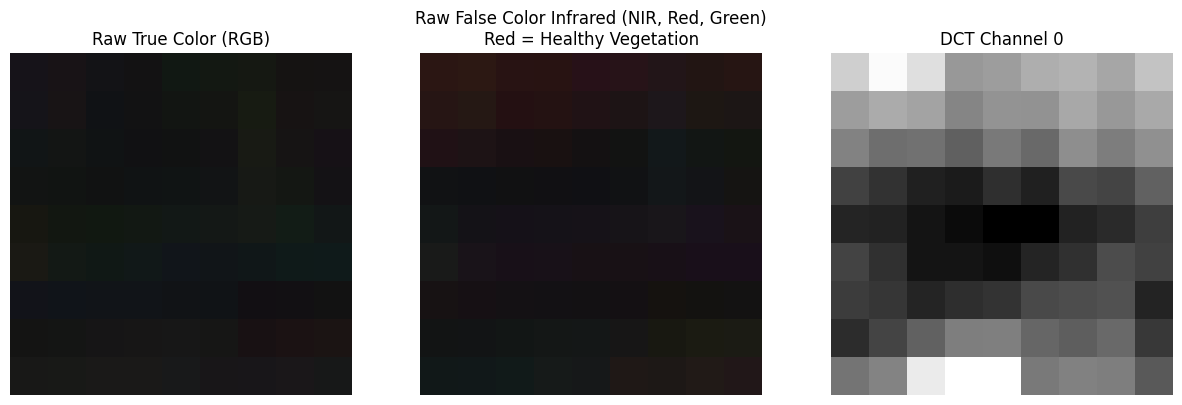


	---Patch 1, shape: torch.Size([10, 9, 9]) (Channels, patch_H, patch_W)

	Statistics:
Band  | Min      | Max      | Mean     | Std     
--------------------------------------------------
B2    | 0.0475   | 0.0952   | 0.0700   | 0.0114
B3    | 0.0516   | 0.1118   | 0.0674   | 0.0139
B4    | 0.0478   | 0.0973   | 0.0673   | 0.0106
B5    | 0.0482   | 0.1021   | 0.0695   | 0.0118
B6    | 0.0482   | 0.0864   | 0.0691   | 0.0116
B7    | 0.0457   | 0.0867   | 0.0740   | 0.0099
B8    | 0.0590   | 0.0927   | 0.0748   | 0.0083
B8A   | 0.0544   | 0.1522   | 0.0908   | 0.0253
B11   | 0.0561   | 0.2030   | 0.1326   | 0.0396
B12   | 0.0706   | 0.2064   | 0.1333   | 0.0327


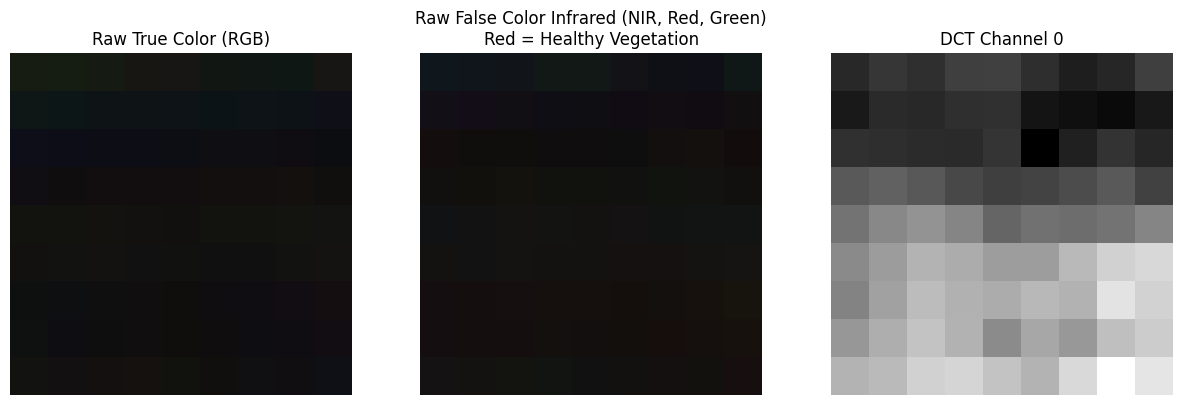

In [ ]:
# import logging
# logging.getLogger("rasterio").setLevel(logging.ERROR) # suppress rasterio warnings

# ---------------------------------------------- Configuration ----------------------------------------------
# Regions of interest
rois = [
    ee.Geometry.Rectangle([12.4, 41.8, 12.42, 41.82]),   # Rome
    ee.Geometry.Rectangle([2.3, 48.8, 2.32, 48.82])  # Paris
    # ... add more regions
]
# Time interval
time_interval = ['2024-06-01', '2024-08-01']
# Spectral bands
bands_to_use = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']


# ---------------------------------------------- Data ----------------------------------------------
# Preprocessing
patch_extractor = PatchExtractor(patch_size=9)  # Patch extraction + optional rescaling
spectral_dct = SpectralDCT(num_bands=len(bands_to_use)).cuda()  # Move DCT matrix to GPU
# Data stream
dataset = Sentinel2Stream(rois, time_interval, bands_to_use, patch_extractor, chunk_months=2)
# DataLoader
loader = DataLoader(
    dataset,
    batch_size=64,      # tune to exploit GPU
    num_workers=1,      # prefetch next chunk of data in background
    prefetch_factor=2,  # buffer 2 batches
    pin_memory=True     # keep data in RAM for faster access
)


# ---------------------------------------------- Testing code ----------------------------------------------
print("Fetching a batch from Earth Engine...")
for batch_idx, batch in enumerate(loader):
    batch = batch.cuda()  # Move batch to GPU
    print(f"\nBatch {batch_idx} successfully fetched! \tBatch tensor shape: {batch.shape} (batch_size, Channels, patch_H, patch_W)")

    # apply DCT to the batch
    dct_batch = spectral_dct(batch)
    
    # Iterate through patches in this batch
    for i in range(len(batch)):
        if i > 1: # check only first 2 patches
            break

        img_tensor_cpu = batch[i].cpu()
        dct_tensor_cpu = dct_batch[i].cpu()
        print(f"\n\tPatch {i}, shape: {img_tensor_cpu.shape} (Channels, patch_H, patch_W)")

        # print stats for all bands
        print("\n\tStatistics:")
        print(f"{'Band':<5} | {'Min':<8} | {'Max':<8} | {'Mean':<8} | {'Std':<8}")
        print("-" * 50)
        for b_idx, name in enumerate(dataset.bands_to_use):
            band_pixels = img_tensor_cpu[b_idx]
            print(f"{name:<5} | {band_pixels.min():.4f}   | {band_pixels.max():.4f}   | {band_pixels.mean():.4f}   | {band_pixels.std():.4f}")
        
        # Plotting
        fig, ax = plt.subplots(1, 3, figsize=(15, 5))

        # True Color (Red=B4, Green=B3, Blue=B2) -> Indices 2, 1, 0
        rgb = img_tensor_cpu[[2, 1, 0], :, :].permute(1, 2, 0).numpy()
        #rgb = np.clip(rgb * 3.0, 0, 1)    # brighten 3x
        ax[0].imshow(rgb)
        ax[0].set_title("Raw True Color (RGB)")
        ax[0].axis('off')

        # False Color Infrared (NIR=B8, Red=B4, Green=B3) -> Indices 6, 2, 1
        # In this view, healthy vegetation appears BRIGHT RED
        fcc = img_tensor_cpu[[6, 2, 1], :, :].permute(1, 2, 0).numpy()
        # fcc = np.clip(fcc * 2.0, 0, 1) # Brighten 2x
        ax[1].imshow(fcc)
        ax[1].set_title("Raw False Color Infrared (NIR, Red, Green)\nRed = Healthy Vegetation")
        ax[1].axis('off')

        # DCT Spectral Signature (plot DCT coefficients for each band)
        dc_component = dct_tensor_cpu[0, :, :].numpy()
        ax[2].imshow(dc_component, cmap='gray')
        ax[2].set_title("DCT Channel 0")
        ax[2].axis('off')

        plt.show()
    
    break   # only fetch and visualize the first batch for testing

# **TEST**